# FINAL PROJECT CODE

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

## Medical Insurance Dataset

In [2]:
med_ins = pd.read_csv("Medical_Insurance.csv")
med_ins.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
med_ins.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

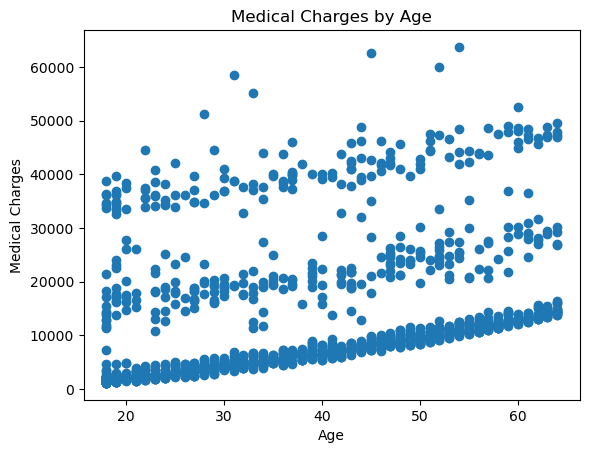

In [4]:
x_age = np.array(med_ins["age"])
y = np.array(med_ins["charges"])

plt.scatter(x_age,y)
plt.xlabel("Age")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Age")
plt.show()

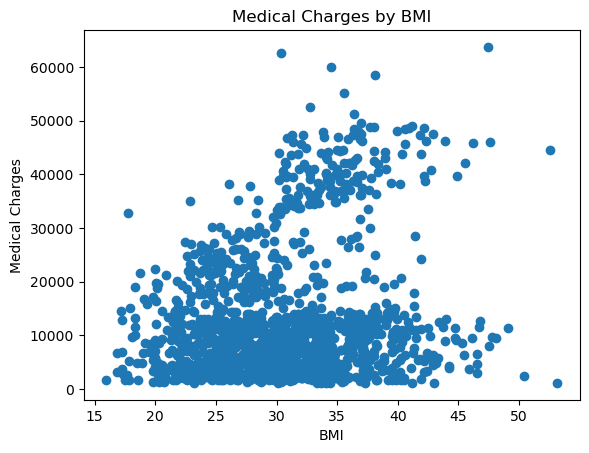

In [5]:
x_bmi = np.array(med_ins["bmi"])
y = np.array(med_ins["charges"])

plt.scatter(x_bmi,y)
plt.xlabel("BMI")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by BMI")
plt.show()

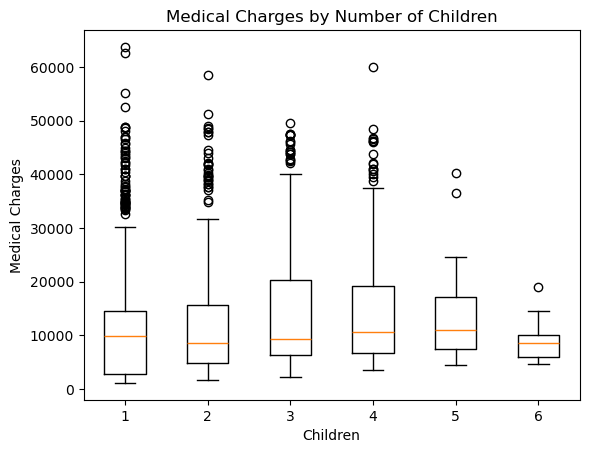

In [6]:
x_children = np.array(med_ins["children"])
y = np.array(med_ins["charges"])

data = [y[x_children == i] for i in np.unique(x_children)]

plt.boxplot(data)
plt.xlabel("Children")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Number of Children")
plt.show()

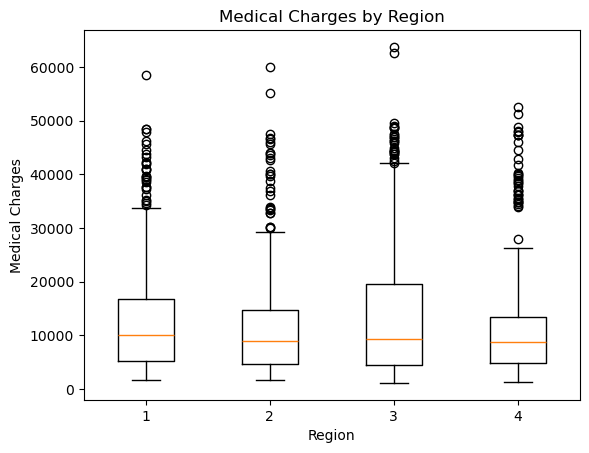

In [7]:
x_region = np.array(med_ins["region"])
y = np.array(med_ins["charges"])

data = [y[x_region == i] for i in np.unique(x_region)]

plt.boxplot(data)
plt.xlabel("Region")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Region")
plt.show()

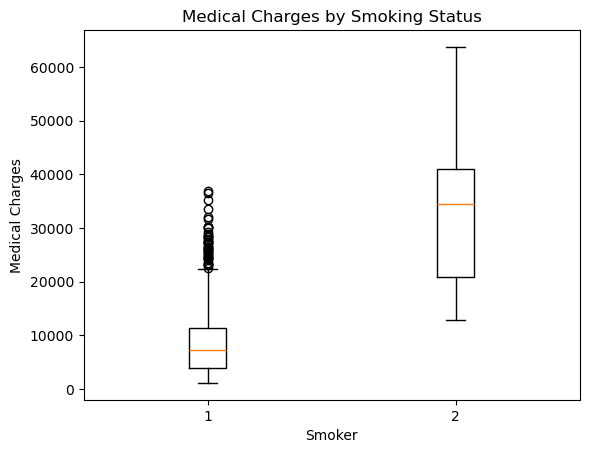

In [8]:
x_smoker = np.array(med_ins["smoker"])
y = np.array(med_ins["charges"])

data = [y[x_smoker == i] for i in np.unique(x_smoker)]

plt.boxplot(data)
plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Smoking Status")
plt.show()

In [9]:
X = pd.get_dummies(med_ins.drop("charges", axis=1), drop_first=True)
X=X.astype(float)
y=med_ins["charges"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=.25,stratify=med_ins["smoker"], random_state=42)

model = LinearRegression().fit(X_train, y_train)

coef_med_ins = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print(coef_med_ins, "\nIntercept:", model.intercept_)


            Feature   Coefficient
0               age    260.071273
1               bmi    312.198416
2          children    430.211482
3          sex_male    -86.273594
4        smoker_yes  23943.532795
5  region_northwest   -435.225419
6  region_southeast  -1349.886261
7  region_southwest   -889.820674 
Intercept: -11205.260240517726


In [10]:
X_train_sm = sm.add_constant(X_train)

model_sm = sm.OLS(y_train, X_train_sm).fit()
model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.742
Method:                 Least Squares   F-statistic:                     360.3
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          1.55e-287
Time:                        20:43:12   Log-Likelihood:                -10165.
No. Observations:                1003   AIC:                         2.035e+04
Df Residuals:                     994   BIC:                         2.039e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.121e+04   1174.808     -9.538      0.000   -1.35e+04   -8899.871
age                260.0713     13.882     18.735      0.000     232.830     287.312
bmi                312.1984     34.142      9.144      0.000     245.199     379.198
children           430.2115    160.406      2.682      0.007     115.438     744.985
sex_male           -86.2736    388.644     -0.222      0.824    -848.930     676.382
smoker_yes        2.394e+04    482.641     49.609      0.000     2.3e+04    2.49e+04
region_northwest  -435.2254    555.948     -0.783      0.434   -1526.192     655.742
region_southeast -1349.8863    557.995     -2.419      0.016   -2444.869    -254.903
region_southwest  -889.8207    558.847     -1.592      0.112   -1986.475     206.834
==============================================================================
Omnibus:                      246.718   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              629.742
Skew:                           1.281   Prob(JB):                    1.79e-137
Kurtosis:                       5.917   Cond. No.                         316.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [11]:
X = X.drop(columns=["sex_male"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.743
Method:                 Least Squares   F-statistic:                     415.2
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          5.01e-290
Time:                        20:43:12   Log-Likelihood:                -10163.
No. Observations:                1003   AIC:                         2.034e+04
Df Residuals:                     995   BIC:                         2.038e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.212e+04   1136.063    -10.665      0.000   -1.43e+04   -9887.272
age                259.6022     13.879     18.704      0.000     232.366     286.838
bmi                339.8566     33.500     10.145      0.000     274.117     405.596
children           426.7669    160.651      2.656      0.008     111.513     742.021
smoker_yes        2.363e+04    478.591     49.381      0.000    2.27e+04    2.46e+04
region_northwest  -354.2252    548.517     -0.646      0.519   -1430.608     722.158
region_southeast  -783.0514    557.934     -1.403      0.161   -1877.913     311.810
region_southwest  -861.3384    551.022     -1.563      0.118   -1942.637     219.960
==============================================================================
Omnibus:                      240.136   Durbin-Watson:                   2.066
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              590.377
Skew:                           1.263   Prob(JB):                    6.33e-129
Kurtosis:                       5.783   Cond. No.                         306.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [12]:
X = X.drop(columns=["region_northwest","region_southeast","region_southwest"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.743
Method:                 Least Squares   F-statistic:                     725.7
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          1.41e-293
Time:                        20:43:12   Log-Likelihood:                -10164.
No. Observations:                1003   AIC:                         2.034e+04
Df Residuals:                     998   BIC:                         2.036e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.227e+04   1104.744    -11.105      0.000   -1.44e+04   -1.01e+04
age          260.0085     13.862     18.756      0.000     232.806     287.211
bmi          327.5784     32.291     10.144      0.000     264.212     390.945
children     435.2402    160.492      2.712      0.007     120.300     750.180
smoker_yes  2.363e+04    477.923     49.449      0.000    2.27e+04    2.46e+04
==============================================================================
Omnibus:                      240.837   Durbin-Watson:                   2.068
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              591.778
Skew:                           1.267   Prob(JB):                    3.14e-129
Kurtosis:                       5.782   Cond. No.                         294.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

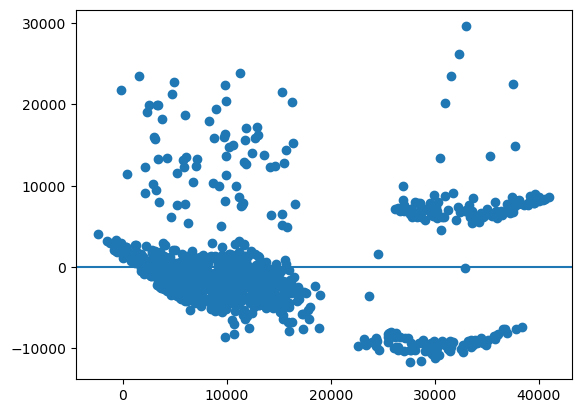

In [13]:
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0)

We can see distinct clusters and patterns arising here which leads us to create interaction terms. 

In [14]:
y=np.log(med_ins["charges"])
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     786.9
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          9.53e-307
Time:                        20:43:12   Log-Likelihood:                -620.70
No. Observations:                1003   AIC:                             1251.
Df Residuals:                     998   BIC:                             1276.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.9783      0.081     85.658      0.000       6.818       7.138
age            0.0348      0.001     34.026      0.000       0.033       0.037
bmi            0.0110      0.002      4.631      0.000       0.006       0.016
children       0.0961      0.012      8.123      0.000       0.073       0.119
smoker_yes     1.5393      0.035     43.676      0.000       1.470       1.608
==============================================================================
Omnibus:                      321.267   Durbin-Watson:                   2.040
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1063.987
Skew:                           1.555   Prob(JB):                    9.08e-232
Kurtosis:                       6.973   Cond. No.                         294.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

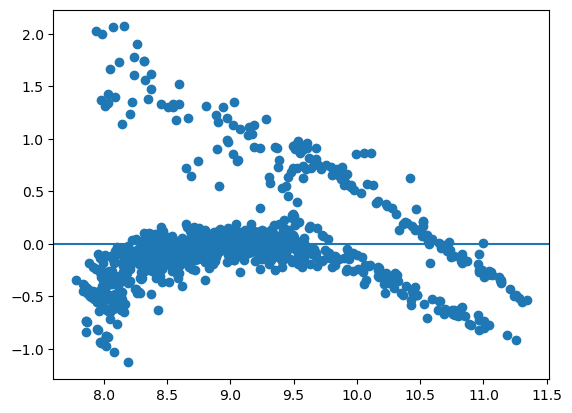

In [15]:
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0)

In [16]:
X["bmi_smoker"] = X["bmi"]*X["smoker_yes"]
X["age_smoker"] = X["age"]*X["smoker_yes"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

model_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.820
Model:                            OLS   Adj. R-squared:                  0.819
Method:                 Least Squares   F-statistic:                     756.8
Date:                Fri, 10 Apr 2026   Prob (F-statistic):               0.00
Time:                        20:43:12   Log-Likelihood:                -474.56
No. Observations:                1003   AIC:                             963.1
Df Residuals:                     996   BIC:                             997.5
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.0546      0.079     89.792      0.0

In [17]:
X = X.drop(columns=["age_smoker"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.774
Method:                 Least Squares   F-statistic:                     688.5
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          2.56e-320
Time:                        20:43:12   Log-Likelihood:                -585.81
No. Observations:                1003   AIC:                             1184.
Df Residuals:                     997   BIC:                             1213.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2779      0.086     84.337      0.000       7.109       7.447
age            0.0350      0.001     35.462      0.000       0.033       0.037
bmi            0.0008      0.003      0.307      0.759      -0.004       0.006
children       0.0981      0.011      8.576      0.000       0.076       0.121
smoker_yes     0.1009      0.173      0.583      0.560      -0.239       0.441
bmi_smoker     0.0472      0.006      8.475      0.000       0.036       0.058
==============================================================================
Omnibus:                      355.475   Durbin-Watson:                   2.010
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1333.341
Skew:                           1.681   Prob(JB):                    2.94e-290
Kurtosis:                       7.539   Cond. No.                         668.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [18]:
X = X.drop(columns=["bmi"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     861.4
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          8.60e-322
Time:                        20:43:12   Log-Likelihood:                -585.86
No. Observations:                1003   AIC:                             1182.
Df Residuals:                     998   BIC:                             1206.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.3008      0.043    170.076      0.000       7.217       7.385
age            0.0351      0.001     35.745      0.000       0.033       0.037
children       0.0981      0.011      8.580      0.000       0.076       0.121
smoker_yes     0.0768      0.154      0.498      0.618      -0.226       0.379
bmi_smoker     0.0480      0.005      9.736      0.000       0.038       0.058
==============================================================================
Omnibus:                      355.334   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1330.479
Skew:                           1.681   Prob(JB):                    1.23e-289
Kurtosis:                       7.531   Cond. No.                         473.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

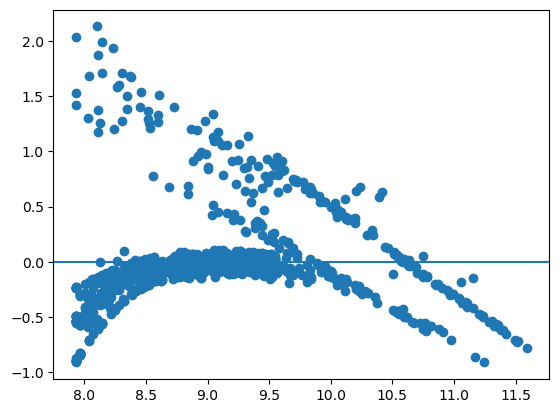

In [19]:
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0)

In [20]:
y=np.log(med_ins["charges"])
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     861.4
Date:                Fri, 10 Apr 2026   Prob (F-statistic):          8.60e-322
Time:                        20:43:12   Log-Likelihood:                -585.86
No. Observations:                1003   AIC:                             1182.
Df Residuals:                     998   BIC:                             1206.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.3008      0.043    170.076      0.000       7.217       7.385
age            0.0351      0.001     35.745      0.000       0.033       0.037
children       0.0981      0.011      8.580      0.000       0.076       0.121
smoker_yes     0.0768      0.154      0.498      0.618      -0.226       0.379
bmi_smoker     0.0480      0.005      9.736      0.000       0.038       0.058
==============================================================================
Omnibus:                      355.334   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1330.479
Skew:                           1.681   Prob(JB):                    1.23e-289
Kurtosis:                       7.531   Cond. No.                         473.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""